# EDA

In [3]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

# Make the repo importable: the local checkout, or a fresh clone on Kaggle/Colab. Then pin versions that must match.
REPO_URL = "https://github.com/BohdanZasymovych/ai-hw3-ai-text-detection.git"
REPO = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "setup_env.py").exists()), None)
if REPO is None:
    REPO = Path("/kaggle/working/hw3" if Path("/kaggle").exists() else "/content/hw3")
    if REPO.exists():
        !git -C {REPO} pull -q
    else:
        !git clone -q --depth 1 {REPO_URL} {REPO}
sys.path.insert(0, str(REPO))

import setup_env

setup_env.install_pins()

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from transformers import AutoTokenizer

from utils import (ARTIFACTS_DIR, DATA_DIR, ENV, LABEL_COLORS, LABEL_ORDER, artifact_dir, cached,
                   ensure_data, ensure_dirs, get_split, plot_label_share, style_features, top_words)

ensure_dirs()
ensure_data()
split = get_split()  # fixed train/val split, made and cached on first use
print(f"env={ENV}  data={DATA_DIR}  artifacts={ARTIFACTS_DIR}")


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
[cache] loaded /home/bohdan/code/ai/hw3-ai-generated-text-detection/artifacts/split.pkl
env=local  data=/home/bohdan/code/ai/hw3-ai-generated-text-detection/data  artifacts=/home/bohdan/code/ai/hw3-ai-generated-text-detection/artifacts


## Data Overview

Load the data and compare the number of samples in train and test.

In [4]:
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")

pd.DataFrame({"samples": [len(train), len(test)]}, index=["train", "test"])

,samples
train,272352
test,25000


Show every language, domain and label present in train.

In [5]:
values = {col: pd.Series(sorted(train[col].unique())) for col in ["lang", "domain", "label"]}
pd.DataFrame(values).fillna("")

,lang,domain,label
0,de-DE,arxiv_papers,ai
1,en-EN,blog_authorship_corpus,fusion
2,,bundestag,human
3,,cnn_news,
4,,euro_court_cases,
5,,gutenberg,
6,,house_of_commons,
7,,student_essays,


## Class Balance

Label share overall and per language.

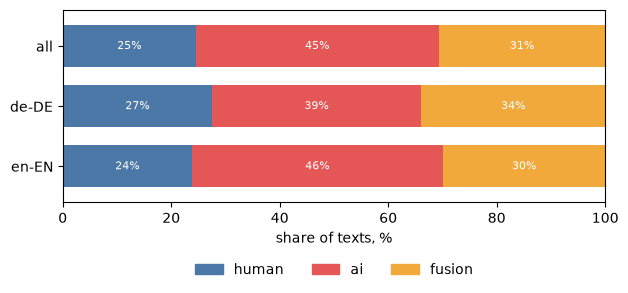

In [6]:
by_lang = pd.concat([train.assign(lang="all"), train])
fig, ax = plt.subplots(figsize=(7, 2.5))
plot_label_share(by_lang, "lang", ax)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=LABEL_COLORS[l]) for l in LABEL_ORDER],
          labels=LABEL_ORDER, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.25), frameon=False)
plt.show()

Label share per domain, one panel per language.

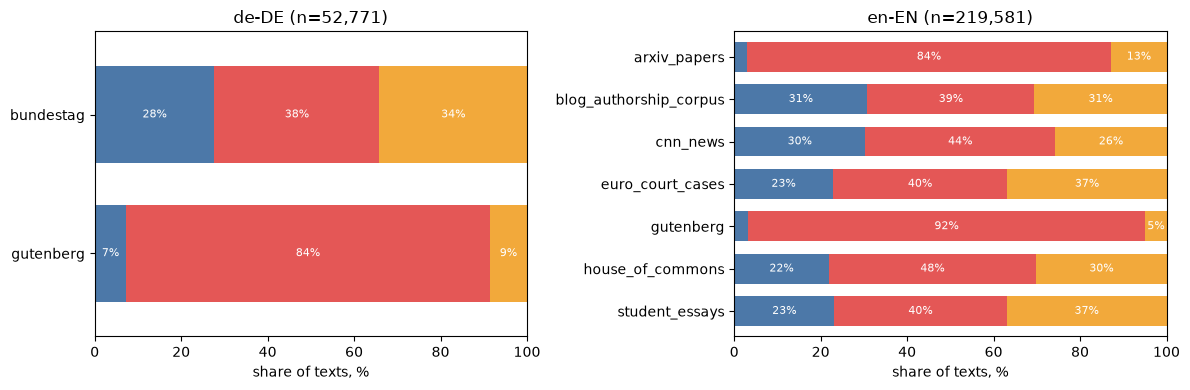

In [7]:
langs = sorted(train["lang"].unique())
fig, axes = plt.subplots(1, len(langs), figsize=(6 * len(langs), 4), sharex=True)
for ax, lang in zip(axes, langs):
    sub = train[train["lang"] == lang]
    plot_label_share(sub, "domain", ax)
    ax.set_title(f"{lang} (n={len(sub):,})")
plt.tight_layout()
plt.show()

## Train vs Test

Share of texts per language and per language/domain in train and test.

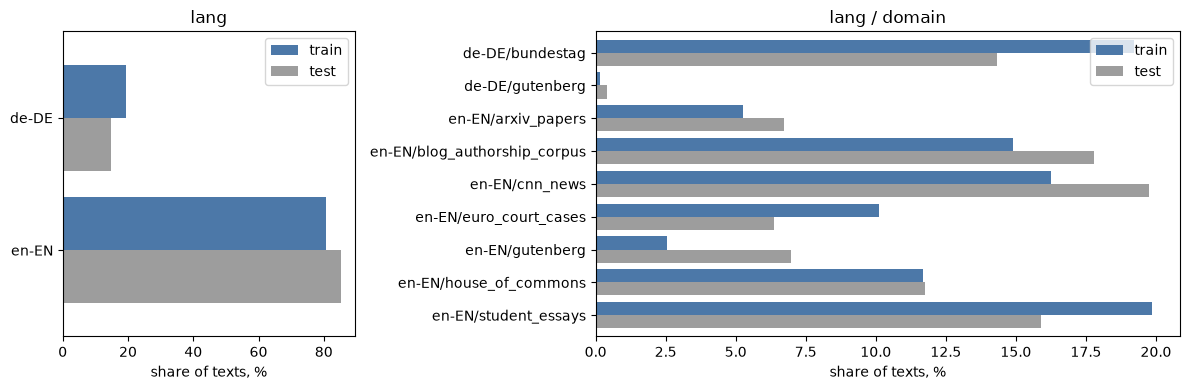

In [8]:
def share(df, cols):
    key = df[cols].astype(str).agg("/".join, axis=1)
    return key.value_counts(normalize=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 2]})
for ax, cols in zip(axes, [["lang"], ["lang", "domain"]]):
    pd.DataFrame({"train": share(train, cols), "test": share(test, cols)}).sort_index().plot.barh(
        ax=ax, color=["#4C78A8", "#9D9D9D"], width=0.8)
    ax.set_title(" / ".join(cols))
    ax.set_xlabel("share of texts, %")
    ax.invert_yaxis()
plt.tight_layout()
plt.show()

## Text Length

Count words and characters per text. The result is cached.

In [9]:
def lengths(df):
    # str.count avoids building a list of words per text (str.split exhausts RAM on 272k long texts)
    return pd.DataFrame({
        "words": df["text"].str.count(r"\S+").astype("int32"),
        "chars": df["text"].str.len().astype("int32"),
    })


train[["words", "chars"]] = cached("eda_lengths_train", lambda: lengths(train), key={"v": 1})
test[["words", "chars"]] = cached("eda_lengths_test", lambda: lengths(test), key={"v": 1})

[cache] loaded /home/bohdan/code/ai/hw3-ai-generated-text-detection/artifacts/eda_lengths_train.pkl
[cache] loaded /home/bohdan/code/ai/hw3-ai-generated-text-detection/artifacts/eda_lengths_test.pkl


Word and character count distributions per label, one panel per language (linear x-axis, clipped at the 99th percentile).

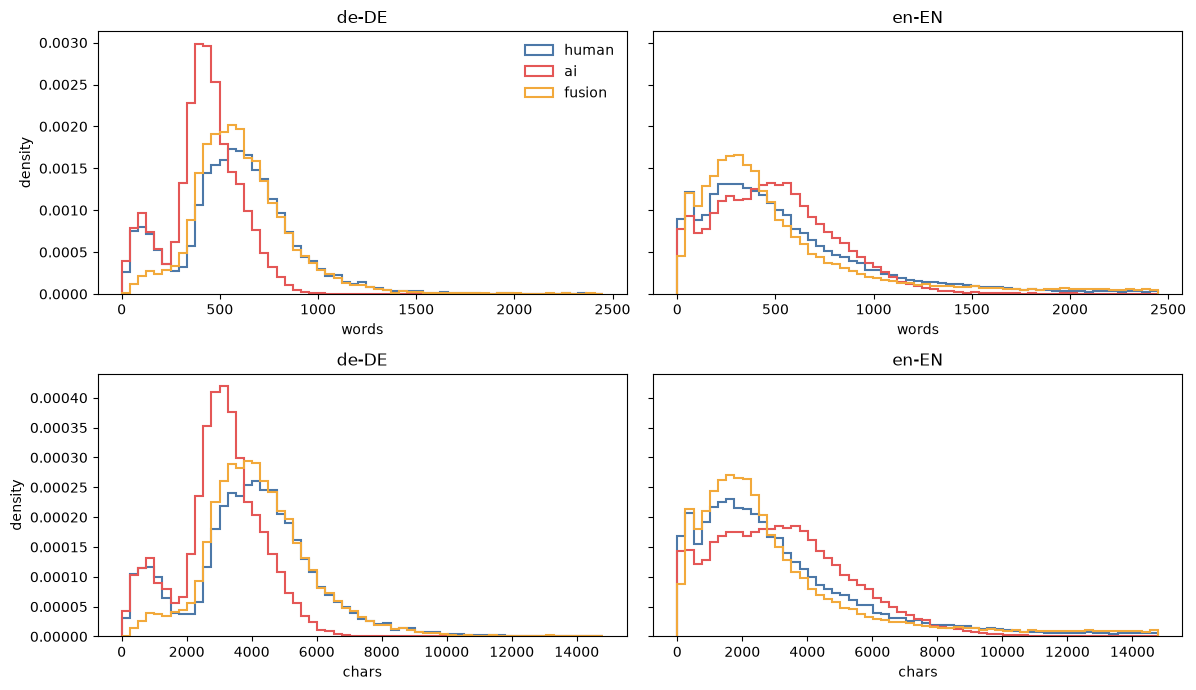

In [10]:
UNITS = ["words", "chars"]
bins = {unit: np.linspace(0, train[unit].quantile(0.99), 60) for unit in UNITS}
fig, axes = plt.subplots(len(UNITS), len(langs), figsize=(6 * len(langs), 3.5 * len(UNITS)), sharey="row", squeeze=False)
for row, unit in zip(axes, UNITS):
    for ax, lang in zip(row, langs):
        for label in LABEL_ORDER:
            values = train.loc[(train["lang"] == lang) & (train["label"] == label), unit]
            ax.hist(values, bins=bins[unit], histtype="step", density=True, color=LABEL_COLORS[label], label=label, lw=1.5)
        ax.set_title(lang)
        ax.set_xlabel(unit)
    row[0].set_ylabel("density")
axes[0, 0].legend(frameon=False)
plt.tight_layout()
plt.show()

Median word and character count per domain and label, to see whether length separates the classes.

In [11]:
for unit in UNITS:
    median = train.pivot_table(index=["lang", "domain"], columns="label", values=unit, aggfunc="median")[LABEL_ORDER]
    display(median.style.set_caption(f"Median {unit}").background_gradient(cmap="Blues", axis=None).format("{:.0f}"))

Word and character count in train vs test, to check that test texts have similar lengths.

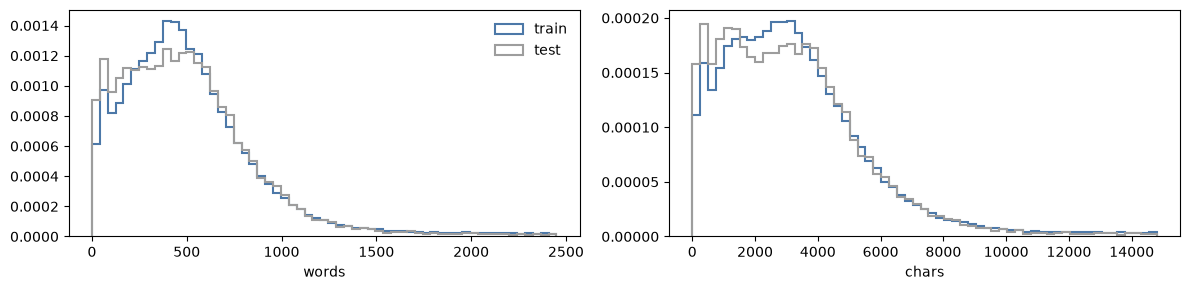

In [12]:
fig, axes = plt.subplots(1, len(UNITS), figsize=(6 * len(UNITS), 3))
for ax, unit in zip(axes, UNITS):
    for name, df, color in [("train", train, "#4C78A8"), ("test", test, "#9D9D9D")]:
        ax.hist(df[unit], bins=bins[unit], histtype="step", density=True, color=color, label=name, lw=1.5)
    ax.set_xlabel(unit)
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()

Count XLM-R tokens on a fixed random sample of train (cached), then show the share of texts above 512 tokens per domain and label.

In [13]:
def count_tokens(texts, batch_size=256):
    counts = []
    for i in range(0, len(texts), batch_size):
        enc = tokenizer(texts[i:i + batch_size], return_attention_mask=False)
        counts += [len(ids) for ids in enc["input_ids"]]
    return np.array(counts)


tokenizer = AutoTokenizer.from_pretrained("xlm-roberta-base")
sample = train.sample(20_000, random_state=42)
token_counts = cached("eda_xlmr_tokens", lambda: count_tokens(sample["text"].tolist()), key={"model": "xlm-roberta-base", "n": 20_000, "seed": 42}, kind="npy")
sample = sample.assign(tokens=token_counts)

over_512 = sample.assign(over=sample["tokens"] > 512).pivot_table(
    index=["lang", "domain"], columns="label", values="over", aggfunc="mean")[LABEL_ORDER] * 100
over_512.style.background_gradient(cmap="Reds", axis=None).format("{:.0f}%")

[cache] loaded /home/bohdan/code/ai/hw3-ai-generated-text-detection/artifacts/eda_xlmr_tokens.npy


## Data Quality

Hash each text to find duplicates cheaply. Count missing values, very short texts, duplicates, and test texts that also appear in train.

In [14]:
train_hash = pd.util.hash_pandas_object(train["text"], index=False).values
test_hash = pd.util.hash_pandas_object(test["text"], index=False).values

quality = pd.DataFrame({
    "train": {
        "rows with missing values": train.isna().any(axis=1).sum(),
        "texts under 10 words": (train["words"] < 10).sum(),
        "duplicate texts (extra copies)": pd.Series(train_hash).duplicated().sum(),
        "duplicates with conflicting labels": (train.groupby(train_hash)["label"].nunique() > 1).sum(),
        "texts also in train": np.nan,
    },
    "test": {
        "rows with missing values": test.isna().any(axis=1).sum(),
        "texts under 10 words": (test["words"] < 10).sum(),
        "duplicate texts (extra copies)": pd.Series(test_hash).duplicated().sum(),
        "duplicates with conflicting labels": np.nan,
        "texts also in train": np.isin(test_hash, train_hash).sum(),
    },
})
quality.style.format("{:,.0f}", na_rep="–")

,train,test
rows with missing values,0,0
texts under 10 words,0,0
duplicate texts (extra copies),0,0
duplicates with conflicting labels,0,–
texts also in train,–,0


## Examples

One random example per label from three domains (first 500 characters), to compare the styles by eye. The total word count of each text is shown next to it.

In [15]:
domains = ["cnn_news", "student_essays", "bundestag"]
rows = train.loc[train["domain"].isin(domains), ["domain", "label"]]
picked = rows.groupby(["domain", "label"]).sample(1, random_state=42).index

examples = train.loc[picked, ["domain", "label", "words", "text"]].assign(text=lambda d: d["text"].str[:500] + " …")
examples["label"] = pd.Categorical(examples["label"], LABEL_ORDER)
examples = examples.sort_values(["domain", "label"]).set_index(["domain", "label"])
examples.style.set_properties(subset=["text"], **{"text-align": "left", "white-space": "pre-wrap", "min-width": "700px"})

## Class Differences

Compute style features on the fixed 20k sample (cached). Each is expressed in standard deviations above or below the median of its own language and domain, so domain effects are removed. The two variation features measure how much the style varies along the text.

In [16]:
features = cached(
    "eda_style_features",
    lambda: pd.DataFrame([style_features(t) for t in sample["text"]], index=sample.index),
    key={"n": 20_000, "seed": 42, "v": 3},
)
domain_median = features.groupby([sample["lang"], sample["domain"]]).transform("median")
z = (features - domain_median) / features.std()

[cache] loaded /home/bohdan/code/ai/hw3-ai-generated-text-detection/artifacts/eda_style_features.pkl


Median style deviation per label. Red means above the domain median, blue below.

In [17]:
table = z.groupby(sample["label"]).median().T[LABEL_ORDER]
limit = table.abs().to_numpy().max()
table.style.background_gradient(cmap="RdBu_r", axis=None, vmin=-limit, vmax=limit).format("{:+.2f}")

label,human,ai,fusion
Sentence length,-0.02,+0.02,-0.01
Word length,-0.34,+0.33,-0.09
Type-token ratio,-0.38,+0.25,-0.25
Punctuation,+0.06,-0.02,-0.02
Digits,+0.18,+0.00,+0.09
Capital letters,+0.15,-0.09,+0.02
Word length variation,-0.12,-0.11,+0.33
Punctuation variation,+0.04,-0.08,+0.11


Features:
- **Sentence length**: words per sentence (sentence ends are `.`, `!`, `?`).
- **Word length**: average number of characters per word.
- **Type-token ratio**: share of distinct words among the first 100 words, a standard measure of vocabulary variety.
- **Punctuation**: punctuation characters per character of text.
- **Digits**: digits per character of text.
- **Capital letters**: uppercase letters per character of text.
- **Word length variation**: how much the average word length changes across 4 equal parts of the text (std / mean). Higher means a less uniform text.
- **Punctuation variation**: the same for the punctuation rate, measured across 4 equal parts of the text.

Words most typical of each class compared with another (English only, smoothed log-odds of document frequency). Human vs ai is the reference for the two pure classes; fusion is compared with both.

In [18]:
en = sample[sample["lang"] == "en-EN"]
texts = {label: en.loc[en["label"] == label, "text"].tolist() for label in LABEL_ORDER}
pairs = [("human", "ai"), ("fusion", "human"), ("fusion", "ai")]
columns = {}
for a, b in pairs:
    top_a, top_b = top_words(texts[a], texts[b])
    columns[f"{a} > {b}"], columns[f"{b} > {a}"] = top_a, top_b
pd.DataFrame(columns)

,human > ai,ai > human,fusion > human,human > fusion,fusion > ai,ai > fusion
0,alia,fostering,fostering,student_name,alia,honorable
1,nbsp,interplay,fosters,spokeswoman,ﬁrst,2023
2,thats,tapestry,emphasizing,expecting,metres,posits
3,student_name,underscores,underscores,fled,summarised,weathered
4,quashed,insights,insights,chelsea,thats,delves
5,cent,resilience,resilience,frank,quashed,elucidating
6,urllink,frameworks,prioritize,kevin,congratulate,investigates
7,dont,amidst,personalized,whats,cent,twinkling
8,discontinued,prioritizes,highlighting,horrible,discontinued,exclaimed
9,anybody,emphasizing,meticulously,midfielder,remitted,echoes


## Cell Sizes

Number of training texts per language, domain and label. The shading uses a log scale, so small cells stay visible.

In [19]:
cell_sizes = train.groupby(["lang", "domain", "label"]).size().unstack()[LABEL_ORDER]
cell_sizes.style.background_gradient(cmap="Blues", axis=None, gmap=np.log10(cell_sizes)).format("{:,}")

Cells sorted by size (log axis). A plain random subsample of 50k keeps about 18% of every cell, so a cell with fewer than about 2,700 texts would have fewer than 500 examples in it. That size is the floor (dashed line): cells left of it are rare, and we would keep all their texts.

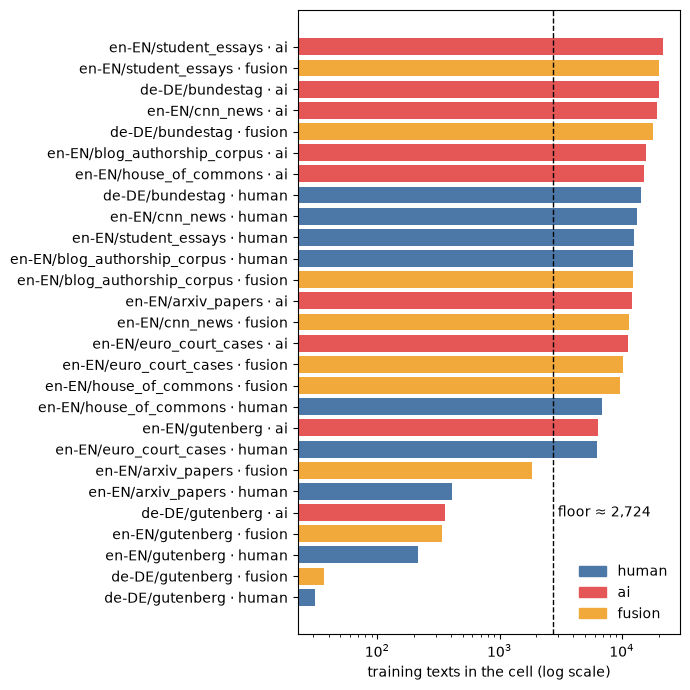

Cells below the floor: 7 of 27, 3,225 texts


In [20]:
SUBSAMPLE_SIZE, MIN_EXAMPLES = 50_000, 500
implied_floor = MIN_EXAMPLES * len(train) / SUBSAMPLE_SIZE

sizes = cell_sizes.stack().sort_values()
names = [f"{lang}/{domain} · {label}" for (lang, domain, label) in sizes.index]
fig, ax = plt.subplots(figsize=(7, 7))
ax.barh(names, sizes.values, color=[LABEL_COLORS[label] for label in sizes.index.get_level_values("label")])
ax.axvline(implied_floor, color="black", ls="--", lw=1)
ax.text(implied_floor * 1.1, 4, f"floor ≈ {implied_floor:,.0f}", va="center")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=LABEL_COLORS[l]) for l in LABEL_ORDER],
          labels=LABEL_ORDER, loc="lower right", frameon=False)
ax.set_xscale("log")
ax.set_xlabel("training texts in the cell (log scale)")
plt.tight_layout()
plt.show()
print(f"Cells below the floor: {(sizes < implied_floor).sum()} of {len(sizes)}, {sizes[sizes < implied_floor].sum():,} texts")

## Train/Validation Split

The fixed split is made once, stratified by language, domain and label, and cached (it is loaded in the setup cell). Check that both parts have the same label shares.

In [21]:
parts = {"train": train.iloc[split["train"]], "val": train.iloc[split["val"]]}
overview = pd.DataFrame({
    name: {"texts": len(df), **{label: (df["label"] == label).mean() * 100 for label in LABEL_ORDER}}
    for name, df in parts.items()
}).T
overview.style.format({"texts": "{:,.0f}", **{label: "{:.1f}%" for label in LABEL_ORDER}})

,texts,human,ai,fusion
train,"245,114",24.5%,44.8%,30.7%
val,"27,238",24.5%,44.8%,30.7%


## Conclusions

- **Data is clean.** No missing values, very short texts, duplicates, or train/test overlap, so no rows need to be dropped.
- **Classes are imbalanced.** `ai` is about 45% of train, `fusion` 31%, `human` 25%.
- **Domain is a shortcut risk.** Gutenberg and arxiv are 84–92% `ai`, while the other domains are much more mixed. A model could learn the domain instead of the writing style.
- **Test differs from train.** Test has more English Gutenberg (about 7% vs 2.5%) and less German, Bundestag and student essays.
- **Length separates `ai` from the rest.** `ai` texts are shorter than `human` and `fusion` in most domains, while `human` and `fusion` have similar lengths. Length alone cannot separate `human` from `fusion`, and it may let a model cheat.
- **Most texts exceed 512 tokens.** Only blogs fit, and student essays partly.
- **Fusion sits between `human` and `ai`.** It keeps human length, names and spelling, but contains AI vocabulary, and its style is less uniform along the text. It is the hardest class, and models that look at local parts of the text are promising.